In [1]:
import kagglehub

# Autenticación con Kaggle
kagglehub.login()

# Descargar dataset
print("Descargando dataset...")
try:
    path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
    print(f"✅ Dataset descargado en: {path}")
except Exception as e:
    print(f"❌ Error: {e}")
    raise

Descargando dataset...
Using Colab cache for faster access to the 'garbage-classification-v2' dataset.
✅ Dataset descargado en: /kaggle/input/garbage-classification-v2
Kaggle credentials set.
Kaggle credentials successfully validated.


In [2]:
try:
    path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
    print(f"\n¡Dataset descargado correctamente!")
    print(f"Ubicación: {path}")
except Exception as e:
    print(f"\nError al descargar: {e}")
    print("Alternativa: Intentando con otro dataset...")
    try:
        path = kagglehub.dataset_download("mostafaabla/garbage-classification")
        print(f"\n¡Dataset alternativo descargado!")
        print(f"Ubicación: {path}")
    except Exception as e2:
        print(f"\nTambién falló: {e2}")
        raise

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.

¡Dataset descargado correctamente!
Ubicación: /kaggle/input/garbage-classification-v2


------

In [3]:
!pip install "pillow<12.0"

  Using cached pillow-11.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.0 kB)
Using cached pillow-11.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.6 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
rembg 2.0.76 requires pillow<13.0.0,>=12.1.0, but you have pillow 11.3.0 which is incompatible.


In [4]:
!pip install rembg

  Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0


In [5]:
!pip install onnxruntime

In [6]:
from rembg import remove
from PIL import Image
import numpy as np
print("✅ Todo cargado correctamente. ¡Listo para eliminar fondos!")

✅ Todo cargado correctamente. ¡Listo para eliminar fondos!


-----

📷 Imagen de prueba seleccionada aleatoriamente: /kaggle/input/garbage-classification-v2/standardized_256/clothes/clothes_943.jpg
(Total de 36777 imágenes disponibles)


  0%|                                               | 0.00/176M [00:00<?, ?B/s]

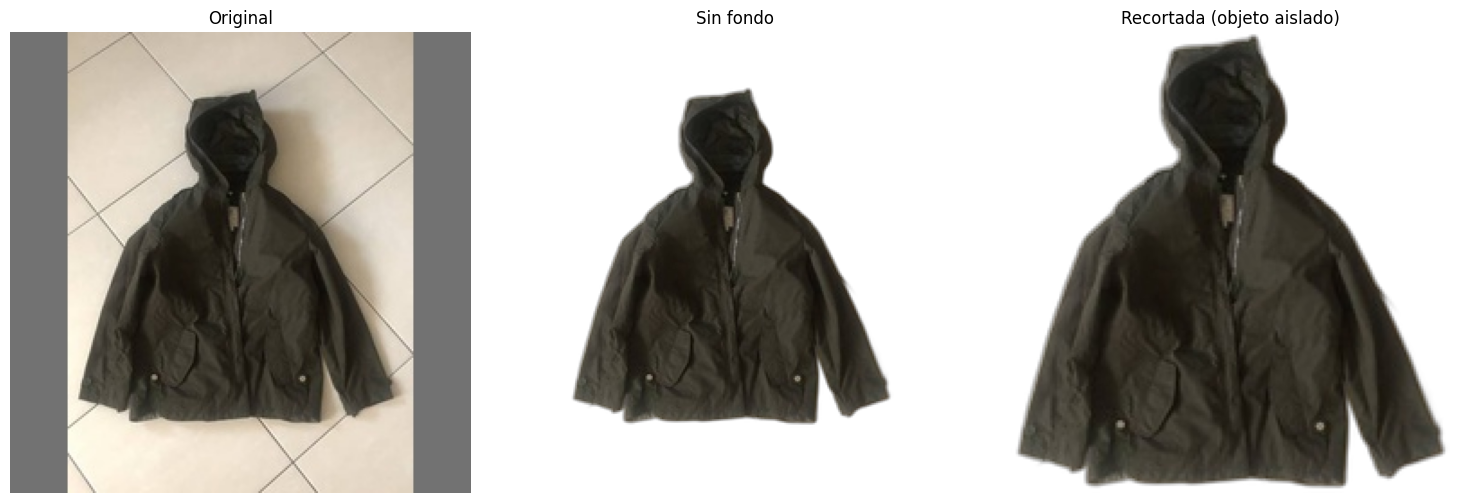

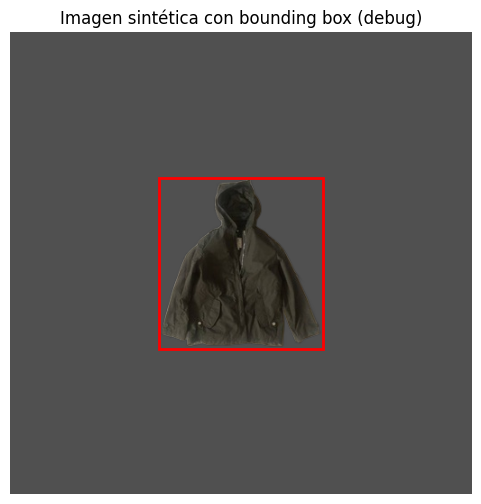

In [7]:
import os
import random
import cv2
import matplotlib.pyplot as plt
from rembg import remove
from PIL import Image
import numpy as np

# ------------------------------------------------------------
# 1. Buscar TODAS las imágenes de prueba dentro del dataset
# ------------------------------------------------------------
def find_all_images(base_path, extensions=('.jpg', '.jpeg', '.png', '.bmp')):
    image_paths = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.lower().endswith(extensions):
                image_paths.append(os.path.join(root, file))
    return image_paths

# ------------------------------------------------------------
# 2. Función para recortar el objeto sin fondo
# ------------------------------------------------------------
def crop_foreground(pil_img_rgba):
    """
    Recorta la imagen alrededor del objeto (área no transparente)
    y devuelve una nueva imagen PIL (RGBA) con el objeto aislado.
    """
    # Convertir a array numpy para procesar
    img_array = np.array(pil_img_rgba)

    # Obtener el canal alfa (transparencia)
    alpha = img_array[:, :, 3]

    # Encontrar las coordenadas de los píxeles con alpha > 0
    coords = np.argwhere(alpha > 0)
    if coords.size == 0:
        # Si no hay objeto, devolver la imagen original sin cambios
        return pil_img_rgba

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    # Recortar la imagen al rectángulo del objeto
    cropped = pil_img_rgba.crop((x_min, y_min, x_max + 1, y_max + 1))
    return cropped

# ------------------------------------------------------------
# 3. BLOQUE PRINCIPAL
# ------------------------------------------------------------
# Usamos la ruta 'path' obtenida del dataset descargado
if 'path' in locals() or 'path' in globals():
    all_images = find_all_images(path)

    if not all_images:
        print("❌ No se encontró ninguna imagen en el dataset.")
    else:
        # Seleccionar UNA imagen aleatoria
        img_path = random.choice(all_images)
        print(f"📷 Imagen de prueba seleccionada aleatoriamente: {img_path}")
        print(f"(Total de {len(all_images)} imágenes disponibles)")

        # ----------------------------------------------------
        # Cargar imagen con OpenCV y convertir a RGB
        # ----------------------------------------------------
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # ----------------------------------------------------
        # Eliminar el fondo con rembg
        # ----------------------------------------------------
        pil_img = Image.fromarray(img_rgb)
        pil_no_bg = remove(pil_img)   # Devuelve imagen PIL con fondo transparente (RGBA)

        # ----------------------------------------------------
        # Recortar la imagen sin fondo para aislar el objeto
        # ----------------------------------------------------
        pil_cropped = crop_foreground(pil_no_bg)

        # ----------------------------------------------------
        # Mostrar las tres imágenes: original, sin fondo, recortada
        # ----------------------------------------------------
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title("Original")
        axes[0].axis('off')

        # Sin fondo (con transparencia visible en matplotlib)
        axes[1].imshow(pil_no_bg)
        axes[1].set_title("Sin fondo")
        axes[1].axis('off')

        # Recortada (objeto aislado)
        axes[2].imshow(pil_cropped)
        axes[2].set_title("Recortada (objeto aislado)")
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()

        # (Opcional) Guardar las imágenes
        # pil_no_bg.save("imagen_sin_fondo.png")
        # pil_cropped.save("objeto_recortado.png")
else:
    print("⚠️ No se encontró la variable 'path' con la ruta del dataset.")


# ------------------------------------------------------------
# 4. CREAR IMAGEN SINTÉTICA CON FONDO GRIS Y BOUNDING BOX
# ------------------------------------------------------------
# Tamaño del lienzo (cuadrado)
CANVAS_SIZE = 512
# Color de fondo (gris medio-oscuro)
BG_COLOR = (80, 80, 80)  # RGB

# 4.1 Crear lienzo gris
canvas = Image.new('RGB', (CANVAS_SIZE, CANVAS_SIZE), BG_COLOR)

# 4.2 Obtener dimensiones del objeto recortado
w, h = pil_cropped.size

# 4.3 Calcular posición para centrar el objeto
x = (CANVAS_SIZE - w) // 2
y = (CANVAS_SIZE - h) // 2

# 4.4 Pegar el objeto sobre el lienzo (usando su canal alfa como máscara)
canvas.paste(pil_cropped, (x, y), pil_cropped)  # tercer argumento = máscara

# 4.5 La bounding box del objeto en el lienzo
bbox = (x, y, x + w, y + h)  # (x_min, y_min, x_max, y_max)

# 4.6 Mostrar la imagen sintética y la bounding box
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.imshow(canvas)

# Dibujar rectángulo de la bounding box (color rojo, grosor 2)
rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor='red', facecolor='none')
ax.add_patch(rect)

ax.set_title("Imagen sintética con bounding box (debug)")
ax.axis('off')
plt.show()

# Opcional: guardar la imagen sintética
# canvas.save("imagen_sintetica.png")

-----

In [10]:
import os

# Elige qué versión quieres usar (cambia si prefieres 'original' o 'standardized_256')
VERSION = 'standardized_384'  # o 'original', 'standardized_256'

version_path = os.path.join(path, VERSION)
print(f"Ruta de la versión seleccionada: {version_path}")

# Listar subdirectorios (las clases)
clases_raw = [d for d in os.listdir(version_path) if os.path.isdir(os.path.join(version_path, d))]
print(f"Clases encontradas en {VERSION}: {clases_raw}")
print(f"Total de clases: {len(clases_raw)}")

Ruta de la versión seleccionada: /kaggle/input/garbage-classification-v2/standardized_384
Clases encontradas en standardized_384: ['metal', 'glass', 'biological', 'paper', 'battery', 'trash', 'cardboard', 'shoes', 'clothes', 'plastic']
Total de clases: 10


In [11]:
from collections import defaultdict

def contar_imagenes_por_clase_version(base_path, extensiones=('.jpg', '.jpeg', '.png', '.bmp')):
    conteo = defaultdict(int)
    # Recorremos todas las subcarpetas (cada una es una clase)
    for clase in os.listdir(base_path):
        clase_path = os.path.join(base_path, clase)
        if not os.path.isdir(clase_path):
            continue
        # Contamos archivos de imagen dentro de esa clase
        for root, dirs, files in os.walk(clase_path):
            for file in files:
                if file.lower().endswith(extensiones):
                    conteo[clase] += 1
    return dict(conteo)

conteo_por_clase = contar_imagenes_por_clase_version(version_path)
print("Número de imágenes por clase (versión {}):".format(VERSION))
for clase, num in sorted(conteo_por_clase.items(), key=lambda x: x[1], reverse=True):
    print(f"  {clase}: {num}")

Número de imágenes por clase (versión standardized_384):
  clothes: 1892
  glass: 1736
  plastic: 1597
  shoes: 1449
  cardboard: 1411
  paper: 1336
  metal: 930
  battery: 756
  biological: 699
  trash: 453


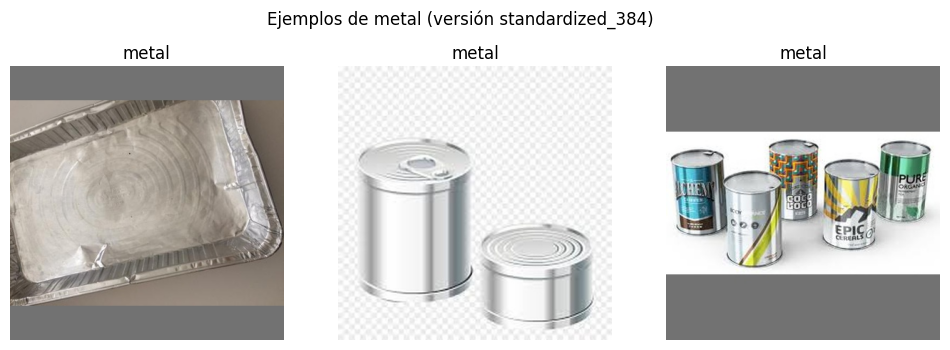

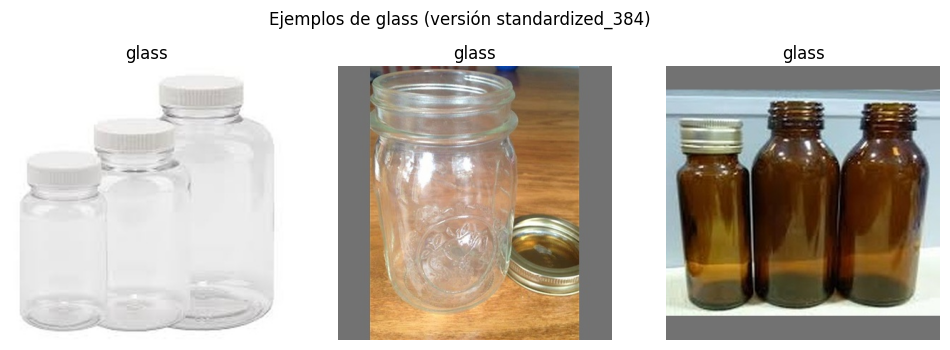

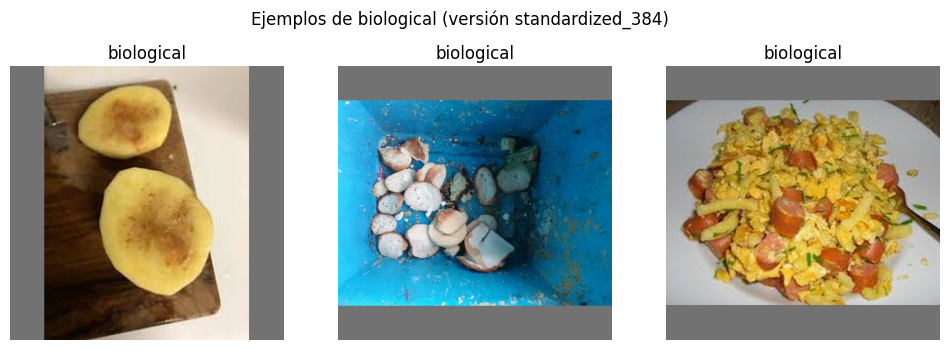

In [12]:
import cv2
import matplotlib.pyplot as plt
import random

def mostrar_ejemplos_version(base_path, clases, num_ejemplos=3):
    for clase in clases:
        clase_path = os.path.join(base_path, clase)
        if not os.path.exists(clase_path):
            print(f"Clase {clase} no encontrada en {base_path}")
            continue
        imagenes = []
        for root, dirs, files in os.walk(clase_path):
            for f in files:
                if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                    imagenes.append(os.path.join(root, f))
        if not imagenes:
            print(f"No hay imágenes para {clase}")
            continue
        muestras = random.sample(imagenes, min(num_ejemplos, len(imagenes)))
        fig, axes = plt.subplots(1, len(muestras), figsize=(12, 4))
        if len(muestras) == 1:
            axes = [axes]
        for ax, img_path in zip(axes, muestras):
            img = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)
            ax.set_title(clase)
            ax.axis('off')
        plt.suptitle(f"Ejemplos de {clase} (versión {VERSION})")
        plt.show()

# Ver las primeras 3 clases (por ejemplo)
clases_mostrar = list(conteo_por_clase.keys())[:3]
mostrar_ejemplos_version(version_path, clases_mostrar)

In [13]:
# Sustituye con los nombres de las clases que quieras (deben coincidir con los listados)
selected_classes = ['cardboard', 'glass', 'biological', 'paper', 'plastic', 'trash']  # Se agrupan luego paper + cardboard y trash + biological

# Verificar que existen
clases_disponibles = set(conteo_por_clase.keys())
clases_seleccionadas = [c for c in selected_classes if c in clases_disponibles]
print("Clases seleccionadas y disponibles:", clases_seleccionadas)
print("Clases no encontradas:", set(selected_classes) - clases_disponibles)

Clases seleccionadas y disponibles: ['cardboard', 'glass', 'biological', 'paper', 'plastic', 'trash']
Clases no encontradas: set()


In [14]:
def get_images_from_classes(base_path, classes, extensions=('.jpg', '.jpeg', '.png', '.bmp')):
    image_paths = []
    for clase in classes:
        clase_path = os.path.join(base_path, clase)
        if not os.path.exists(clase_path):
            print(f"Advertencia: {clase_path} no existe")
            continue
        for root, dirs, files in os.walk(clase_path):
            for file in files:
                if file.lower().endswith(extensions):
                    image_paths.append(os.path.join(root, file))
    return image_paths

# Ahora obtenemos todas las imágenes de las clases seleccionadas, usando la versión elegida
selected_images = get_images_from_classes(version_path, selected_classes)
print(f"Total de imágenes seleccionadas: {len(selected_images)}")
# Mostrar algunas rutas de ejemplo
for p in selected_images[:5]:
    print(p)

Total de imágenes seleccionadas: 7232
/kaggle/input/garbage-classification-v2/standardized_384/cardboard/cardboard_255.jpg
/kaggle/input/garbage-classification-v2/standardized_384/cardboard/cardboard_1194.jpg
/kaggle/input/garbage-classification-v2/standardized_384/cardboard/cardboard_984.jpg
/kaggle/input/garbage-classification-v2/standardized_384/cardboard/cardboard_547.jpg
/kaggle/input/garbage-classification-v2/standardized_384/cardboard/cardboard_70.jpg


-----

In [18]:
import os
import cv2
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from rembg import remove
import shutil
from tqdm import tqdm

# Configuración
CANVAS_SIZE = 640            # Tamaño del lienzo (cuadrado) para las imágenes sintéticas
NUM_SYNTHETIC_PER_IMAGE = 4  # Número de variantes por imagen original (ajusta según recursos)
TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Directorio donde se guardará el dataset YOLO
OUTPUT_DIR = "/content/yolo_dataset"  # en Colab
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Mapeo clase -> ID (según el orden alfabético, para consistencia)
class_names = sorted(selected_classes)  # lista de nombres
class_to_id = {name: idx for idx, name in enumerate(class_names)}
num_classes = len(class_names)
print("Mapeo de clases a IDs:")
for name, idx in class_to_id.items():
    print(f"  {idx}: {name}")

Mapeo de clases a IDs:
  0: biological
  1: cardboard
  2: glass
  3: paper
  4: plastic
  5: trash


In [19]:
def crop_foreground(pil_img_rgba):
    """
    Recorta el objeto (área no transparente) de una imagen PIL RGBA.
    Devuelve la imagen recortada (PIL) y las coordenadas del bounding box (x, y, w, h) en píxeles.
    """
    img_array = np.array(pil_img_rgba)
    alpha = img_array[:, :, 3]
    coords = np.argwhere(alpha > 0)
    if coords.size == 0:
        # Si no hay objeto, devolvemos la imagen original y su bbox (toda la imagen)
        return pil_img_rgba, (0, 0, pil_img_rgba.width, pil_img_rgba.height)
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)
    cropped = pil_img_rgba.crop((x_min, y_min, x_max + 1, y_max + 1))
    bbox = (x_min, y_min, x_max - x_min + 1, y_max - y_min + 1)
    return cropped, bbox

def remove_background_and_crop(image_path):
    """
    Lee una imagen, elimina fondo con rembg, recorta el objeto.
    Devuelve (objeto_recortado_PIL, bbox_pixeles) o (None, None) si falla.
    """
    try:
        img_bgr = cv2.imread(image_path)
        if img_bgr is None:
            return None, None
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img_rgb)
        pil_no_bg = remove(pil_img)   # RGBA
        cropped, bbox = crop_foreground(pil_no_bg)
        return cropped, bbox
    except Exception as e:
        print(f"Error procesando {image_path}: {e}")
        return None, None

def apply_augmentation(object_pil, canvas_size, rotate_range=(-30, 30), scale_range=(0.6, 1.2)):
    """
    Aplica rotación y escalado aleatorio al objeto, y lo coloca en una posición aleatoria dentro del lienzo.
    Devuelve (imagen_final_PIL, bbox_normalizado) donde bbox_normalizado = (x_center, y_center, width, height) en [0,1].
    """
    # Convertir a numpy para manipular
    obj_np = np.array(object_pil)
    h, w = obj_np.shape[:2]

    # Generar ángulo de rotación
    angle = np.random.uniform(*rotate_range)
    # Factor de escala
    scale = np.random.uniform(*scale_range)

    # Matriz de rotación (centro en el centro del objeto)
    center = (w/2, h/2)
    rot_mat = cv2.getRotationMatrix2D(center, angle, scale)
    # Rotar la imagen (con relleno para mantener tamaño)
    cos = np.abs(rot_mat[0, 0])
    sin = np.abs(rot_mat[0, 1])
    new_w = int((h * sin) + (w * cos))
    new_h = int((h * cos) + (w * sin))
    rot_mat[0, 2] += (new_w / 2) - center[0]
    rot_mat[1, 2] += (new_h / 2) - center[1]

    rotated = cv2.warpAffine(obj_np, rot_mat, (new_w, new_h), borderMode=cv2.BORDER_CONSTANT, borderValue=(0,0,0,0))

    # Obtener el bounding box del objeto rotado (área no transparente)
    alpha_rot = rotated[:, :, 3]
    coords = np.argwhere(alpha_rot > 0)
    if coords.size == 0:
        return None, None
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)
    obj_cropped = rotated[y_min:y_max+1, x_min:x_max+1, :]  # RGBA

    # Ahora colocar en un lienzo de tamaño canvas_size
    canvas = Image.new('RGB', (canvas_size, canvas_size), color=(80, 80, 80))  # gris
    obj_pil = Image.fromarray(obj_cropped)
    obj_w, obj_h = obj_pil.size

    # Posición aleatoria, pero asegurando que el objeto quede dentro del canvas
    max_x = canvas_size - obj_w
    max_y = canvas_size - obj_h
    if max_x < 0 or max_y < 0:
        # Si el objeto es más grande que el canvas, redimensionar
        scale_factor = min(canvas_size / obj_w, canvas_size / obj_h) * 0.9
        new_w = int(obj_w * scale_factor)
        new_h = int(obj_h * scale_factor)
        obj_pil = obj_pil.resize((new_w, new_h), Image.Resampling.LANCZOS)
        obj_w, obj_h = obj_pil.size
        max_x = canvas_size - obj_w
        max_y = canvas_size - obj_h

    x = random.randint(0, max_x) if max_x > 0 else 0
    y = random.randint(0, max_y) if max_y > 0 else 0

    # Pegar objeto sobre el canvas con máscara alfa
    # El objeto tiene canal alfa, pero ya hemos recortado y puede tener transparencia en bordes
    # Convertimos a RGBA para pegar con máscara
    canvas_rgba = Image.new('RGBA', (canvas_size, canvas_size), (80,80,80,255))
    if obj_pil.mode != 'RGBA':
        obj_pil = obj_pil.convert('RGBA')
    canvas_rgba.paste(obj_pil, (x, y), obj_pil)  # usar alfa como máscara
    canvas_rgb = canvas_rgba.convert('RGB')

    # Calcular bounding box normalizado (centro, ancho, alto)
    x_center = (x + obj_w/2) / canvas_size
    y_center = (y + obj_h/2) / canvas_size
    width = obj_w / canvas_size
    height = obj_h / canvas_size
    # Asegurar valores dentro de [0,1]
    x_center = np.clip(x_center, 0, 1)
    y_center = np.clip(y_center, 0, 1)
    width = np.clip(width, 0, 1)
    height = np.clip(height, 0, 1)

    return canvas_rgb, (x_center, y_center, width, height)

In [20]:
# Crear estructura de directorios
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(OUTPUT_DIR, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, 'labels', split), exist_ok=True)

# Contadores
total_generated = 0
image_counter = 0
# Lista para almacenar todas las rutas generadas (para hacer split después)
all_generated_paths = []  # cada elemento: (image_path, label_path, split)

# Procesar cada imagen original
for img_path in tqdm(selected_images, desc="Procesando imágenes originales"):
    # Eliminar fondo y recortar
    obj_pil, bbox = remove_background_and_crop(img_path)
    if obj_pil is None:
        continue

    # Determinar la clase a partir de la ruta (nombre de carpeta padre)
    # Obtenemos el nombre de la clase de la ruta
    class_name = os.path.basename(os.path.dirname(img_path))
    if class_name not in class_to_id:
        # Si está dentro de subcarpetas como train/test, puede que la clase esté un nivel más arriba
        # Intentamos obtener el nombre de la carpeta padre del padre
        parent_dir = os.path.basename(os.path.dirname(os.path.dirname(img_path)))
        if parent_dir in class_to_id:
            class_name = parent_dir
        else:
            # Si no, asignar a "unknown" o saltar
            print(f"Clase no reconocida para {img_path}")
            continue
    class_id = class_to_id[class_name]

    # Generar varias variantes sintéticas
    for _ in range(NUM_SYNTHETIC_PER_IMAGE):
        # Aplicar aumentos
        synth_img, bbox_norm = apply_augmentation(obj_pil, CANVAS_SIZE)
        if synth_img is None:
            continue

        # Guardar imagen y etiqueta
        image_counter += 1
        img_filename = f"syn_{image_counter:08d}.jpg"
        label_filename = f"syn_{image_counter:08d}.txt"

        # Asignar split aleatorio
        rand = random.random()
        if rand < TRAIN_RATIO:
            split = 'train'
        elif rand < TRAIN_RATIO + VAL_RATIO:
            split = 'val'
        else:
            split = 'test'

        img_save_path = os.path.join(OUTPUT_DIR, 'images', split, img_filename)
        label_save_path = os.path.join(OUTPUT_DIR, 'labels', split, label_filename)

        # Guardar imagen
        synth_img.save(img_save_path, quality=95)
        # Guardar etiqueta (formato YOLO)
        with open(label_save_path, 'w') as f:
            # class_id x_center y_center width height
            f.write(f"{class_id} {bbox_norm[0]:.6f} {bbox_norm[1]:.6f} {bbox_norm[2]:.6f} {bbox_norm[3]:.6f}\n")

        all_generated_paths.append((img_save_path, label_save_path, split))
        total_generated += 1

print(f"Total de imágenes sintéticas generadas: {total_generated}")

Procesando imágenes originales: 100%|██████████| 7232/7232 [6:38:32<00:00,  3.31s/it]

Total de imágenes sintéticas generadas: 28928


In [21]:
# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os
import time
import shutil

# Rutas
dataset_path = "/content/yolo_dataset"
drive_destination = "/content/drive/MyDrive/garbage_datasets"  # Cambia si quieres otra carpeta

# Crear carpeta de destino si no existe
os.makedirs(drive_destination, exist_ok=True)

# Nombre del archivo zip con timestamp
timestamp = time.strftime("%Y%m%d_%H%M%S")
zip_filename = f"yolo_dataset_{timestamp}.zip"
zip_path = os.path.join(drive_destination, zip_filename)

# Comprimir el dataset (excluyendo archivos innecesarios)
print(f"Comprimiendo {dataset_path} -> {zip_path} ...")
!zip -r "{zip_path}" "{dataset_path}" -x "*.ipynb_checkpoints*" "*.DS_Store" -q
print("✅ Compresión completada.")

# Tamaño del archivo
size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"Archivo creado: {zip_path} ({size_mb:.2f} MB)")

# Copiar también dataset.yaml por separado
# shutil.copy2(os.path.join(dataset_path, "dataset.yaml"), os.path.join(drive_destination, "dataset.yaml"))
# print("✅ dataset.yaml copiado a Drive.")

# Instrucciones para restaurar en el futuro
print("\n📌 Para restaurar este dataset en una futura sesión de Colab:")
print("   from google.colab import drive")
print("   drive.mount('/content/drive')")
print(f"   !unzip -q '/content/drive/MyDrive/garbage_datasets/{zip_filename}' -d /content/")
print("   # Ahora tendrás /content/yolo_dataset")

Mounted at /content/drive
Comprimiendo /content/yolo_dataset -> /content/drive/MyDrive/garbage_datasets/yolo_dataset_20260702_171802.zip ...
✅ Compresión completada.
Archivo creado: /content/drive/MyDrive/garbage_datasets/yolo_dataset_20260702_171802.zip (526.70 MB)


FileNotFoundError: [Errno 2] No such file or directory: '/content/yolo_dataset/dataset.yaml'